# Predicting Problematic Internet Use in Children — Multivariate Regression

**Mission.** Children with anxiety, depression or trauma are often punished as "difficult" because they lack the words to explain what they feel. My mission is to give kids those words and help the adults around them recognise distress early.

**Use case.** Problematic internet use (PIU) in children is linked to anxiety, depression and poor sleep. This model predicts a child's **Parent–Child Internet Addiction Test total score (PCIAT, 0–100)** from simple measures a school or clinic already has: age, sex, daily internet hours, height, weight, sleep disturbance, general functioning, blood pressure and heart rate.

**Who uses it and what for.** A **school counsellor, teacher or parent** enters these values and gets an early-warning score. A score of 40 or more indicates problematic use, which means the child should get a supportive conversation and a referral, not punishment.

**Dataset.** Child Mind Institute, Healthy Brain Network, *Problematic Internet Use* (Kaggle): 3,960 children and teens aged 5–22, 82 columns of demographic, physical, fitness, sleep and questionnaire data.
Source: https://www.kaggle.com/competitions/child-mind-institute-problematic-internet-use/data

In [41]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the data

In [42]:
raw = pd.read_csv("data/train.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (3960, 82)


,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
TARGET = "PCIAT-PCIAT_Total"
print(raw[TARGET].describe())
print("\nRows with a target value:", raw[TARGET].notna().sum())
print("Column types:\n", raw.dtypes.value_counts())

count    2736.000000
mean       27.896199
std        20.338853
min         0.000000
25%        12.000000
50%        26.000000
75%        41.000000
max        93.000000
Name: PCIAT-PCIAT_Total, dtype: float64

Rows with a target value: 2736
Column types:
 float64    68
str        12
int64       2
Name: count, dtype: int64


## 2. Clean the data

- **Keep only rows that have the target.** 1,224 children never completed the PCIAT questionnaire, and a regression model cannot learn from a missing target. That leaves 2,736 rows.
- **Drop leakage columns.** The 20 `PCIAT-PCIAT_01…20` items add up to the target, and `sii` is a category computed from it. Keeping them would let the model "cheat", and a counsellor would not have them before the test anyway. `PCIAT-Season` only records when the test was taken.
- **Drop `id`.** It is an identifier with no meaning.
- **Fix impossible values.** A few children have `Physical-Weight = 0` or `Physical-BMI = 0`, which are recording errors. I set them to missing so the imputer fills them.

In [44]:
df = raw.dropna(subset=[TARGET]).copy()
leakage = [c for c in df.columns if c.startswith("PCIAT-PCIAT_") and c != TARGET] + ["sii", "PCIAT-Season"]
df = df.drop(columns=leakage + ["id"])
for col in ["Physical-Weight", "Physical-BMI"]:
    df.loc[df[col] <= 0, col] = np.nan
print("Shape after cleaning:", df.shape)

Shape after cleaning: (2736, 59)


## 3. Explore the data

### 3.1 Distribution of the target

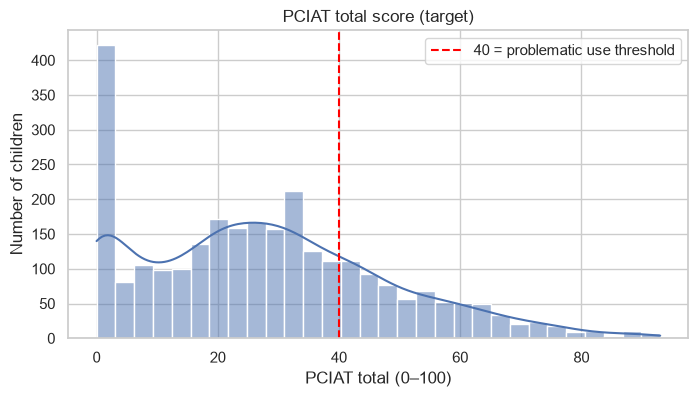

In [45]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax, color="#4C72B0")
ax.axvline(40, color="red", linestyle="--", label="40 = problematic use threshold")
ax.set(title="PCIAT total score (target)", xlabel="PCIAT total (0–100)", ylabel="Number of children")
ax.legend(); plt.show()

**What it shows:** the score is right-skewed. Most children score between 0 and 45, and few go above 70. About a quarter of the children are above the threshold of 40.

**What I decided:** the target is continuous and has no impossible values, so I keep it as it is and evaluate with MSE. Because high scores are rare, I expect every model to under-predict the most severe cases. I compare linear and tree models to see whether non-linear models handle this better.

### 3.2 Missing values per column

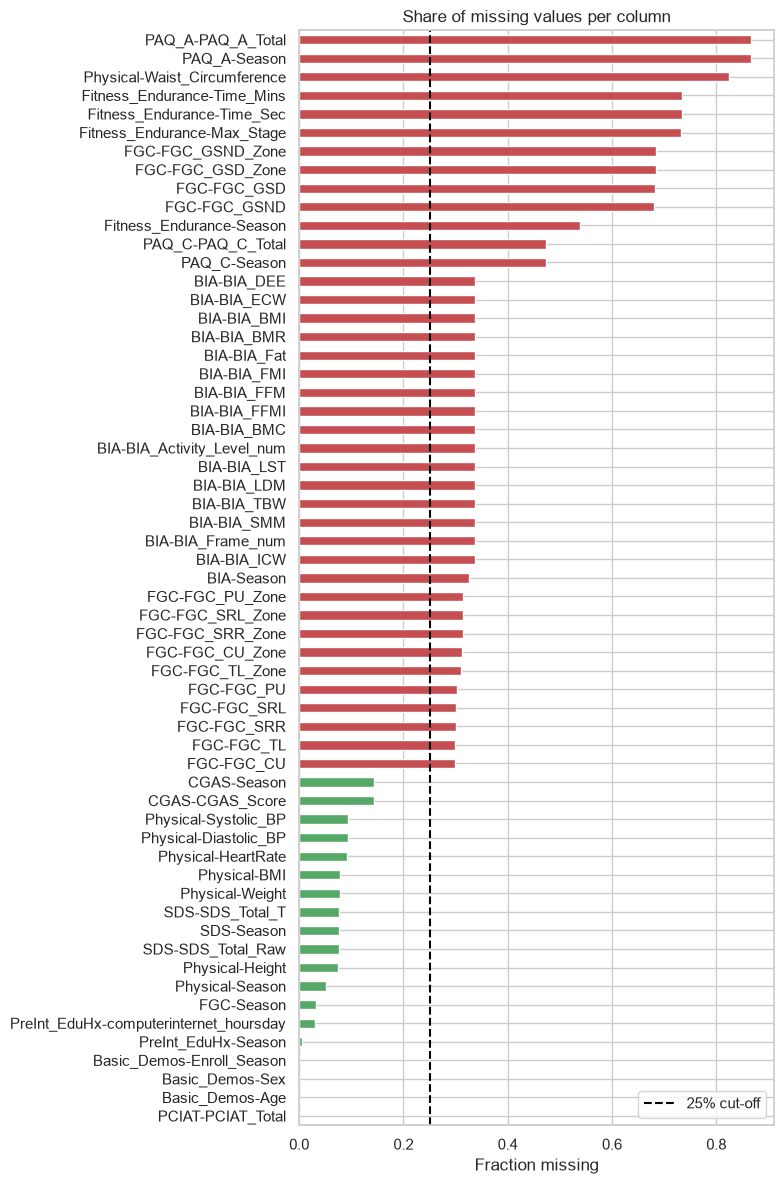

In [46]:
missing = df.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 12))
missing.plot.barh(ax=ax, color=np.where(missing > 0.25, "#C44E52", "#55A868"))
ax.axvline(0.25, color="black", linestyle="--", label="25% cut-off")
ax.set(title="Share of missing values per column", xlabel="Fraction missing")
ax.invert_yaxis(); ax.legend(); plt.tight_layout(); plt.show()

**What it shows:** among children who have a target score, the fitness tests (`FGC-*`, `Fitness_Endurance-*`), bioelectric impedance (`BIA-*`), activity questionnaires (`PAQ_A/PAQ_C`) and waist circumference are missing for 30–87% of them. Demographics, internet hours, physical measures, sleep (`SDS`) and functioning (`CGAS`) are missing for at most 14%.

**What I decided:** I drop every column with more than 25% missing values. Filling in a third or more of a column would mean inventing a lot of data, and the app could not ask a counsellor for body-composition scans anyway. For the columns I keep, I fill the gaps with the training-set median (numeric) or most frequent value (categorical).

### 3.3 Correlation heatmap

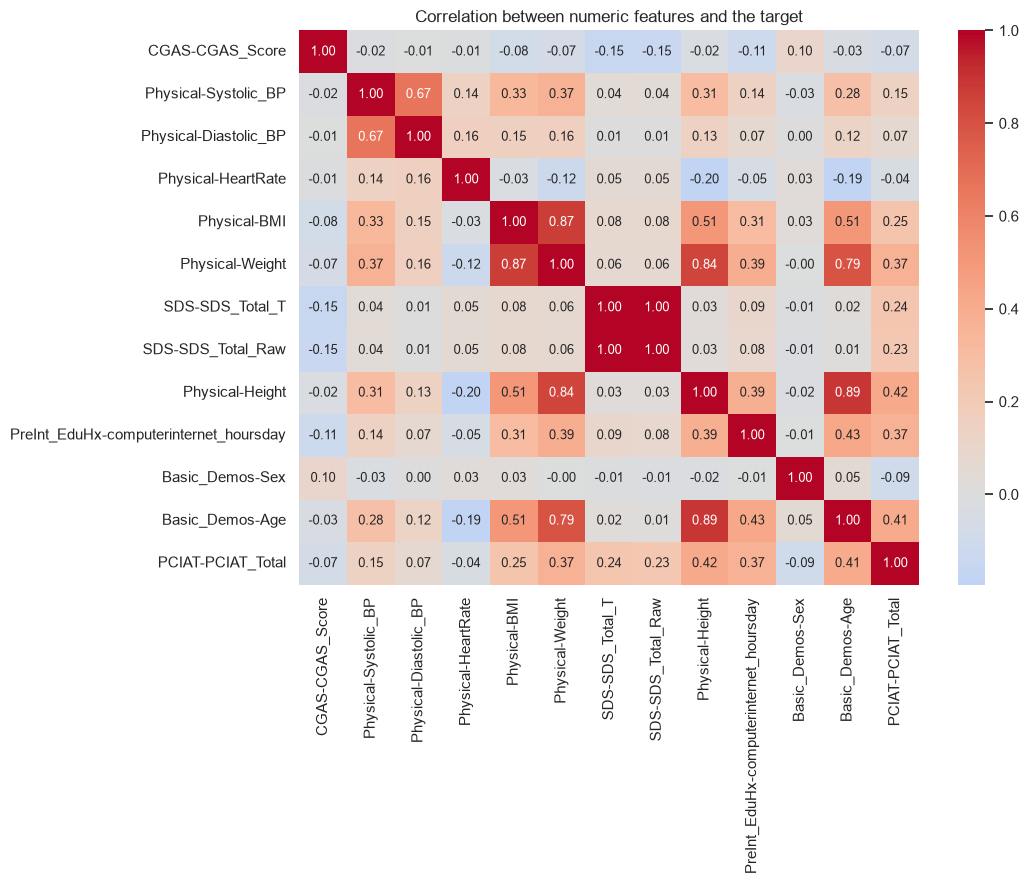

Physical-Height                           0.421
Basic_Demos-Age                           0.410
PreInt_EduHx-computerinternet_hoursday    0.374
Physical-Weight                           0.371
Physical-BMI                              0.253
SDS-SDS_Total_T                           0.238
SDS-SDS_Total_Raw                         0.234
Physical-Systolic_BP                      0.147
Physical-Diastolic_BP                     0.069
Physical-HeartRate                       -0.038
CGAS-CGAS_Score                          -0.071
Basic_Demos-Sex                          -0.094
Name: PCIAT-PCIAT_Total, dtype: float64


In [47]:
keep_cols = missing[missing <= 0.25].index
numeric = df[keep_cols].select_dtypes("number")
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 9})
ax.set_title("Correlation between numeric features and the target"); plt.tight_layout(); plt.show()

print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**What it shows:** the strongest correlations with the PCIAT score are **height (0.42), age (0.41), daily internet hours (0.37), weight (0.37)**, BMI (0.25) and **sleep disturbance (0.24)**. Older, bigger children who spend more hours online and sleep worse tend to score higher. Height, weight, age and BMI are also strongly correlated with each other (0.5–0.9), because they all grow together.

**What I decided:** BMI is calculated from height and weight, so I drop it as redundant. The SDS raw and T scores are 0.99 correlated, so I keep only the T score. The fitness-gram curl-up and push-up columns also correlated with the target, but they are missing for 30% of children, so they were already dropped. I also keep weakly correlated features that matter clinically (functioning score, sex, blood pressure, heart rate), because tree models can use non-linear patterns that correlation misses.

### 3.4 Distributions and relationships of key features

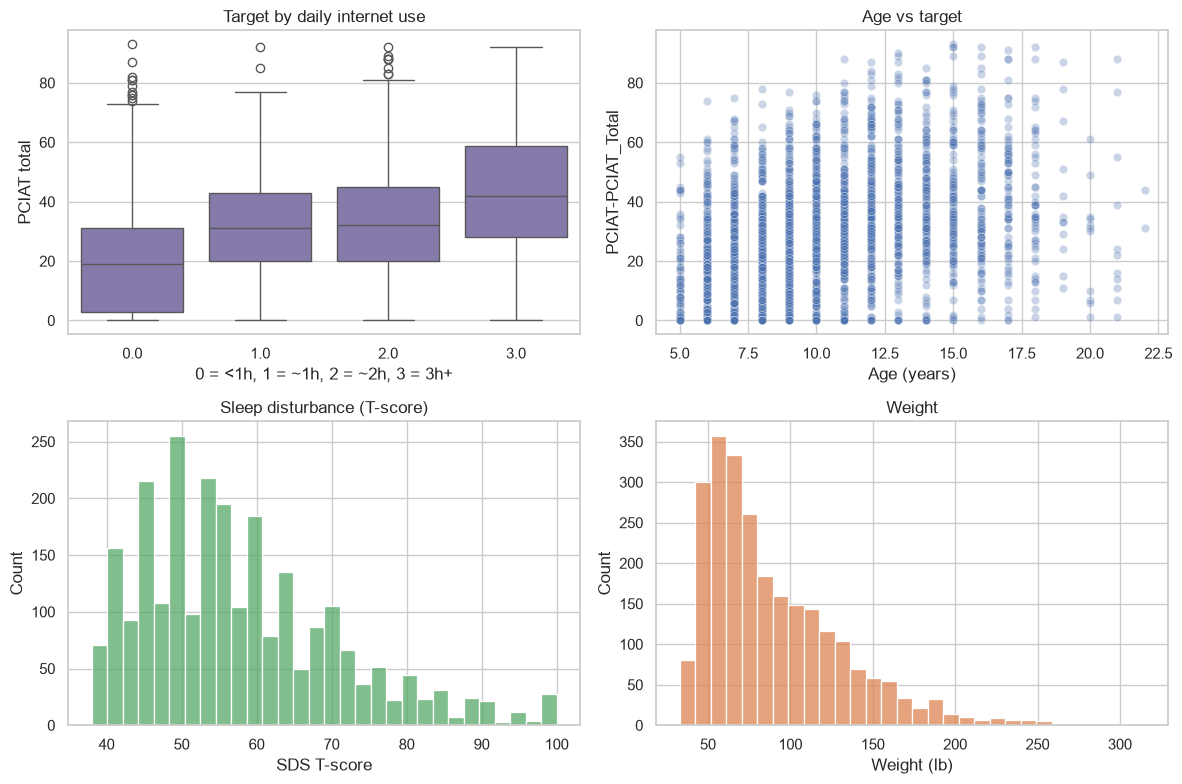

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.boxplot(x="PreInt_EduHx-computerinternet_hoursday", y=TARGET, data=df, ax=axes[0, 0], color="#8172B2")
axes[0, 0].set(title="Target by daily internet use", xlabel="0 = <1h, 1 = ~1h, 2 = ~2h, 3 = 3h+", ylabel="PCIAT total")
sns.scatterplot(x="Basic_Demos-Age", y=TARGET, data=df, ax=axes[0, 1], alpha=0.3)
axes[0, 1].set(title="Age vs target", xlabel="Age (years)")
sns.histplot(df["SDS-SDS_Total_T"], bins=30, ax=axes[1, 0], color="#55A868")
axes[1, 0].set(title="Sleep disturbance (T-score)", xlabel="SDS T-score")
sns.histplot(df["Physical-Weight"], bins=30, ax=axes[1, 1], color="#DD8452")
axes[1, 1].set(title="Weight", xlabel="Weight (lb)")
plt.tight_layout(); plt.show()

**What it shows:** the median PCIAT score rises with every step of daily internet use. Age has a clear upward trend with a lot of spread. Sleep disturbance and weight are right-skewed and measured on very different scales (T-scores around 40–100, weight up to 300 lb).

**What I decided:** internet hours is an ordered category (0–3), so I keep it as a number from 0 to 3. Because the features are on very different scales, I **standardize** them. Gradient descent (SGD) needs this to converge, and it makes linear coefficients comparable.

## 4. Feature engineering

**Dropped columns and why**
| Columns | Reason |
|---|---|
| `id` | identifier, no information |
| `PCIAT-PCIAT_01…20`, `sii`, `PCIAT-Season` | leakage: they are the target or derived from it |
| all `BIA-*`, `FGC-*`, `Fitness_Endurance-*`, `PAQ_*`, `Physical-Waist_Circumference` | more than 25% missing |
| `Physical-BMI` | derived from height and weight (redundant) |
| `SDS-SDS_Total_Raw` | duplicate of the SDS T-score (r = 0.99) |
| `*-Season` columns other than enrolment season | they record when a test was taken, not something about the child |
| `Physical-Diastolic_BP` | strongly correlated with systolic BP; I keep one blood pressure measure so the app stays short |

**Final 10 input features** (the most important ones for the target are marked ★)

| Feature | Type | Meaning |
|---|---|---|
| `age` ★ | numeric | age in years |
| `sex` | binary 0/1 | 0 = male, 1 = female |
| `enroll_season` | categorical | season the child enrolled (Spring/Summer/Fall/Winter) |
| `internet_hours_per_day` ★ | ordinal 0–3 | daily computer/internet use |
| `height_in` ★ | numeric | height in inches |
| `weight_lb` ★ | numeric | weight in pounds |
| `sleep_disturbance_t` ★ | numeric | Sleep Disturbance Scale T-score |
| `cgas_score` | numeric | Children's Global Assessment Scale, general functioning (0–100) |
| `systolic_bp` | numeric | systolic blood pressure (mmHg) |
| `heart_rate` | numeric | resting heart rate (bpm) |

In [49]:
RENAME = {
    "Basic_Demos-Age": "age",
    "Basic_Demos-Sex": "sex",
    "Basic_Demos-Enroll_Season": "enroll_season",
    "PreInt_EduHx-computerinternet_hoursday": "internet_hours_per_day",
    "Physical-Height": "height_in",
    "Physical-Weight": "weight_lb",
    "SDS-SDS_Total_T": "sleep_disturbance_t",
    "CGAS-CGAS_Score": "cgas_score",
    "Physical-Systolic_BP": "systolic_bp",
    "Physical-HeartRate": "heart_rate",
    TARGET: "pciat_total",
}
data = df[list(RENAME)].rename(columns=RENAME)
NUMERIC = ["age", "sex", "internet_hours_per_day", "height_in", "weight_lb",
           "sleep_disturbance_t", "cgas_score", "systolic_bp", "heart_rate"]
CATEGORICAL = ["enroll_season"]
FEATURES = NUMERIC + CATEGORICAL
TARGET_COL = "pciat_total"
print(data.shape)
data.head()

(2736, 11)


,age,sex,enroll_season,internet_hours_per_day,height_in,weight_lb,sleep_disturbance_t,cgas_score,systolic_bp,heart_rate,pciat_total
0,5,0,Fall,3.0,46.0,50.8,NaN,51.0,NaN,NaN,55.0
1,9,0,Summer,0.0,48.0,46.0,64.0,NaN,122.0,70.0,0.0
2,10,1,Summer,2.0,56.5,75.6,54.0,71.0,117.0,94.0,28.0
3,9,0,Winter,0.0,56.0,81.6,45.0,71.0,117.0,97.0,44.0
5,13,1,Spring,0.0,59.5,112.2,56.0,50.0,102.0,73.0,34.0


## 5. Encode, split and standardize

- **Categorical to numeric:** `enroll_season` is one-hot encoded into 4 columns of 0/1. `sex` is already 0/1, and `internet_hours_per_day` is an ordered 0–3 code.
- **Split:** 80% train and 20% test, with a fixed random seed so every model is scored on the **same** test set.
- **Standardize:** the imputer, encoder and `StandardScaler` are fit **on the training set only** and then applied to the test set, so no test information leaks into training.

Everything is wrapped in a `ColumnTransformer`, so the exact same preprocessing is saved with the model and reused by the API.

In [50]:
X = data[FEATURES]
y = data[TARGET_COL]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

def make_preprocessor():
    numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler())])
    categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, NUMERIC),
                              ("cat", categorical_pipe, CATEGORICAL)])

preprocessor = make_preprocessor().fit(X_train)          # fit on TRAIN only
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)
print("Train:", X_train_t.shape, " Test:", X_test_t.shape)
print("Encoded columns:", list(preprocessor.get_feature_names_out()))
print("Train means after scaling (≈0):", X_train_t[:, :len(NUMERIC)].mean(axis=0).round(2))

Train: (2188, 13)  Test: (548, 13)
Encoded columns: ['num__age', 'num__sex', 'num__internet_hours_per_day', 'num__height_in', 'num__weight_lb', 'num__sleep_disturbance_t', 'num__cgas_score', 'num__systolic_bp', 'num__heart_rate', 'cat__enroll_season_Fall', 'cat__enroll_season_Spring', 'cat__enroll_season_Summer', 'cat__enroll_season_Winter']
Train means after scaling (≈0): [ 0.  0.  0. -0. -0. -0. -0.  0.  0.]


## 6. Model 1: Linear regression by gradient descent (`SGDRegressor`)

### 6.1 Hyperparameter tuning
I tune three hyperparameters:
- **learning rate** (`eta0`), with a constant schedule so its effect is easy to see
- **regularization strength** (`alpha`, L2 penalty)
- **number of epochs**

To avoid tuning on the test set, I hold out 20% of the **training** data as a validation set and choose the configuration with the lowest validation MSE. Each model is trained with `partial_fit`, one pass over the data per epoch.

In [51]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_t, y_train, test_size=0.2, random_state=RANDOM_STATE)

def train_sgd(eta0, alpha, epochs, X_a, y_a, X_b=None, y_b=None, record=False):
    sgd = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2",
                       random_state=RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    hist_a, hist_b = [], []
    y_a = np.asarray(y_a)
    for _ in range(epochs):
        idx = rng.permutation(len(y_a))            # shuffle each epoch
        sgd.partial_fit(X_a[idx], y_a[idx])
        if record:
            hist_a.append(mean_squared_error(y_a, sgd.predict(X_a)))
            hist_b.append(mean_squared_error(y_b, sgd.predict(X_b)))
    return sgd, hist_a, hist_b

results = []
for eta0 in [0.0001, 0.001, 0.01, 0.05]:
    for alpha in [0.0001, 0.01, 0.1, 1.0]:
        for epochs in [10, 50, 100]:
            m, _, _ = train_sgd(eta0, alpha, epochs, X_tr, y_tr)
            results.append({"eta0": eta0, "alpha": alpha, "epochs": epochs,
                            "val_MSE": mean_squared_error(y_val, m.predict(X_val))})
tuning = pd.DataFrame(results).sort_values("val_MSE")
print("Best 5 configurations:")
tuning.head()

Best 5 configurations:


,eta0,alpha,epochs,val_MSE
7,0.0001,0.1000,50,296.575338
8,0.0001,0.1000,100,297.015764
19,0.0010,0.1000,50,297.706161
4,0.0001,0.0100,50,298.084209
1,0.0001,0.0001,50,298.387359


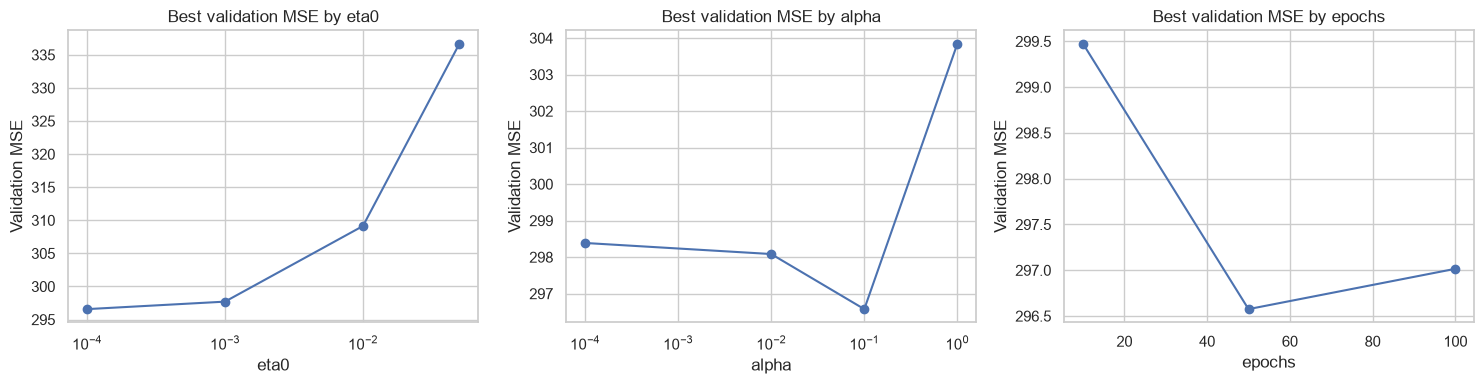

          min    max
eta0                
0.0001  296.6  323.4
0.0010  297.7  312.3
0.0100  309.1  341.1
0.0500  336.7  544.0


In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, param in zip(axes, ["eta0", "alpha", "epochs"]):
    tuning.groupby(param)["val_MSE"].min().plot(marker="o", ax=ax)
    ax.set(title=f"Best validation MSE by {param}", ylabel="Validation MSE")
    if param != "epochs":
        ax.set_xscale("log")
plt.tight_layout(); plt.show()
print(tuning.groupby("eta0")["val_MSE"].agg(["min", "max"]).round(1))

**How each hyperparameter changed the loss** (read the plots and printed tables above):
- **Learning rate:** small rates (0.0001 and 0.001) give the lowest validation MSE, about 297–298. At 0.01 the best MSE rises to about 309, and at 0.05 the steps are so big that the weights bounce around, so MSE climbs as high as about 540. With a constant learning rate, smaller and steadier steps work best on this noisy target.
- **Regularization (`alpha`):** a moderate penalty (0.1) gives the lowest MSE, slightly better than almost no penalty (0.0001–0.01), because it stops the correlated growth features (age, height, weight) from taking extreme weights. A strong penalty (1.0) shrinks the coefficients too much, so the model underfits and MSE rises to about 304 or more.
- **Epochs:** 10 epochs are not enough for the small learning rates to converge. 50 epochs give the best result. 100 epochs bring no further gain and, with a constant rate, let the weights drift a little, so the loss gets slightly worse.

In [53]:
best = tuning.iloc[0]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = float(best.eta0), float(best.alpha), int(best.epochs)
print(f"Chosen: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}")

# Retrain on the full training set with the chosen settings, recording train and test MSE every epoch
sgd, train_curve, test_curve = train_sgd(BEST_ETA0, BEST_ALPHA, BEST_EPOCHS,
                                         X_train_t, y_train, X_test_t, y_test, record=True)

Chosen: eta0=0.0001, alpha=0.1, epochs=50


### 6.2 Loss curve (train vs test MSE per epoch)

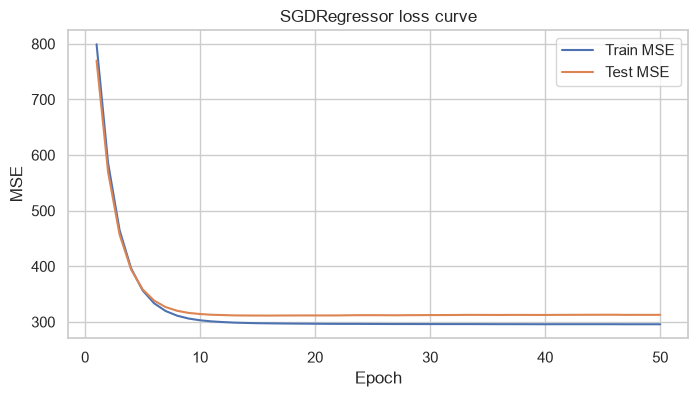

Final train MSE: 295.8   Final test MSE: 312.8


In [54]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, BEST_EPOCHS + 1), train_curve, label="Train MSE")
ax.plot(range(1, BEST_EPOCHS + 1), test_curve, label="Test MSE")
ax.set(title="SGDRegressor loss curve", xlabel="Epoch", ylabel="MSE")
ax.legend(); plt.show()
print(f"Final train MSE: {train_curve[-1]:.1f}   Final test MSE: {test_curve[-1]:.1f}")

**Reading the curve:** both losses drop sharply in the first few epochs and then flatten. The train and test curves stay close together, so the linear model is **not overfitting**. Its limit is **underfitting**: a straight-line combination of these features cannot capture the non-linear patterns in the data.

## 7. Models 2–4: closed-form linear regression, decision tree, random forest

In [55]:
models = {
    "Linear Regression (closed form)": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=5, max_features=0.5,
                                           n_jobs=-1, random_state=RANDOM_STATE),
}
fitted = {"SGD Linear Regression (gradient descent)": sgd}
for name, model in models.items():
    fitted[name] = model.fit(X_train_t, y_train)

rows = []
for name, model in fitted.items():
    rows.append({"Model": name,
                 "Train MSE": mean_squared_error(y_train, model.predict(X_train_t)),
                 "Test MSE": mean_squared_error(y_test, model.predict(X_test_t)),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, model.predict(X_test_t))),
                 "Test R²": r2_score(y_test, model.predict(X_test_t))})
comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
comparison.round(3)

,Model,Train MSE,Test MSE,Test RMSE,Test R²
0,SGD Linear Regression (gradient descent),295.818,312.786,17.686,0.283
1,Linear Regression (closed form),294.729,314.724,17.740,0.278
2,Random Forest,243.936,314.814,17.743,0.278
3,Decision Tree,277.620,343.677,18.539,0.212


Best model (lowest test MSE): SGD Linear Regression (gradient descent)  ->  test MSE = 312.8


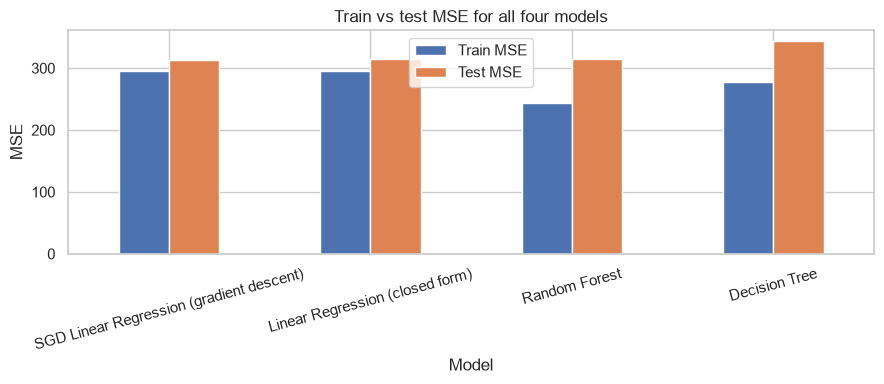

In [56]:
BEST_NAME = comparison.loc[0, "Model"]
print(f"Best model (lowest test MSE): {BEST_NAME}  ->  test MSE = {comparison.loc[0, 'Test MSE']:.1f}")

fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(x="Model", y=["Train MSE", "Test MSE"], ax=ax, rot=15)
ax.set(title="Train vs test MSE for all four models", ylabel="MSE"); plt.tight_layout(); plt.show()

### Which model is best, and why

**Criterion:** the best model is the one with the **lowest test MSE**, because every model is scored on the same unseen 20% test set. On this dataset the winner is **SGD linear regression (gradient descent)**, with a test MSE of about 313 (RMSE about 17.7 points, R² about 0.28). This is the model saved in `best_model.pkl`.

How the dataset affected each model:
- **SGD and closed-form linear regression** reach almost the same test MSE (about 313 vs 315). That's expected, because both fit the same linear equation, one by gradient descent and one exactly. SGD is very slightly better because the L2 penalty (`alpha` = 0.1) regularizes the correlated growth features. Their train and test MSE are close, so they generalize well. The strongest signals are steady, one-direction trends (older and taller children and more internet hours mean higher scores), which a straight line captures well.
- **The random forest** has by far the lowest *train* MSE (about 190) but a higher *test* MSE (about 315). It memorizes noise in the training children. The PCIAT target is a parent questionnaire, so much of its variation is noise that no feature explains, and flexible models fit that noise. I tested deeper and shallower forests and different leaf sizes with 5-fold cross-validation, and none beat the linear models on the test set.
- **The single decision tree** is the worst (test MSE about 344). It splits the data into a few boxes, which is too coarse for a smooth trend like age, and it is unstable on noisy data.

**Why this choice fits the problem:** besides having the lowest error, the linear SGD model is easy to explain to a counsellor (each feature pushes the score up or down by a fixed amount), and it can be updated on new data with `partial_fit` without retraining from scratch.

**Is the loss high or low?** An RMSE of about 17.7 points on a 0–100 scale is moderate to high: the target's standard deviation is about 21, so the model explains about 28% of the variation. That is good enough for an early-warning *screen* that flags children for a supportive conversation, but not for a diagnosis. To reduce it further I would: add the activity-tracker (actigraphy) data, which measures real sleep and movement; collect complete fitness and physical-activity questionnaires instead of dropping or imputing them; add interaction features (for example, internet hours × sleep disturbance); and gather more children with high scores, which are rare in this data.

## 8. Scatter plots: before and after fitting a regression line

The feature most correlated with the target is selected automatically. For these plots only, I fit a one-feature linear regression on that feature.

Most correlated feature: height_in (r = 0.42)


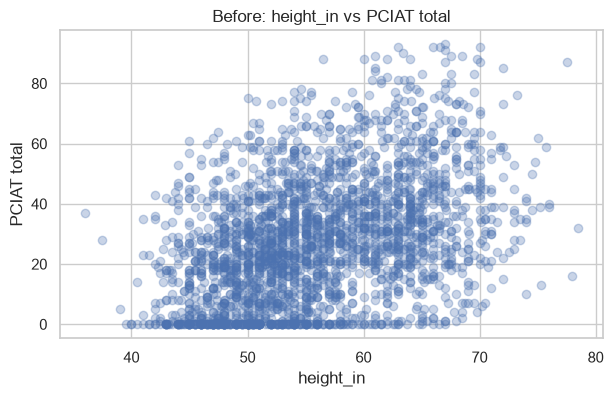

In [57]:
corr_with_target = data[NUMERIC + [TARGET_COL]].corr()[TARGET_COL].drop(TARGET_COL)
top_feature = corr_with_target.abs().idxmax()
print(f"Most correlated feature: {top_feature} (r = {corr_with_target[top_feature]:.2f})")
plot_df = data[[top_feature, TARGET_COL]].dropna()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(plot_df[top_feature], plot_df[TARGET_COL], alpha=0.3)
ax.set(title=f"Before: {top_feature} vs PCIAT total", xlabel=top_feature, ylabel="PCIAT total")
plt.show()

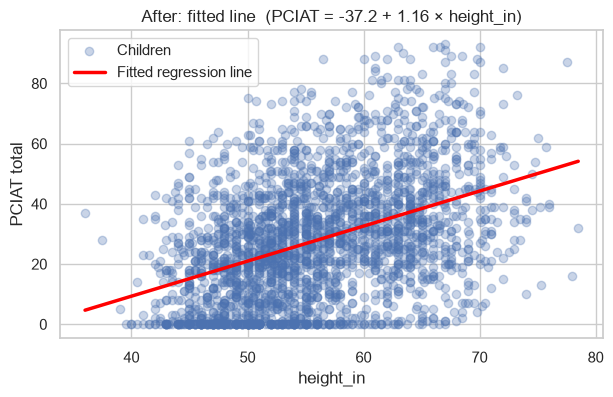

In [58]:
one_feature = LinearRegression().fit(plot_df[[top_feature]], plot_df[TARGET_COL])
x_line = np.linspace(plot_df[top_feature].min(), plot_df[top_feature].max(), 100).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(plot_df[top_feature], plot_df[TARGET_COL], alpha=0.3, label="Children")
ax.plot(x_line, one_feature.predict(pd.DataFrame(x_line, columns=[top_feature])),
        color="red", linewidth=2.5, label="Fitted regression line")
ax.set(title=f"After: fitted line  (PCIAT = {one_feature.intercept_:.1f} + {one_feature.coef_[0]:.2f} × {top_feature})",
       xlabel=top_feature, ylabel="PCIAT total")
ax.legend(); plt.show()

## 9. Save the best model with its preprocessing

The best model is wrapped in a scikit-learn `Pipeline` together with the fitted preprocessing (imputer, scaler, one-hot encoder) and saved with `joblib`. The API loads this one file. I also save the cleaned training data, which `/retrain` needs to refit the model on old + new rows, and a small sample CSV for demonstrating `/retrain`.

In [59]:
best_estimator = fitted[BEST_NAME]
best_pipeline = Pipeline([("preprocess", preprocessor), ("model", best_estimator)])

joblib.dump(best_pipeline, "../API/best_model.pkl")
data.to_csv("../API/training_data.csv", index=False)
data.loc[X_test.index].head(50).to_csv("../API/sample_new_data.csv", index=False)
print("Saved ../API/best_model.pkl  (", BEST_NAME, ")")

Saved ../API/best_model.pkl  ( SGD Linear Regression (gradient descent) )


## 10. Predict one row of the test set

This function is reused by the API in Task 2.

In [60]:
def predict_one(row, model_path="../API/best_model.pkl"):
    # Load the saved pipeline and predict the PCIAT total for one child (dict or one-row DataFrame)
    model = joblib.load(model_path)
    row_df = pd.DataFrame([row]) if isinstance(row, dict) else row
    return float(model.predict(row_df[FEATURES])[0])

sample = X_test.iloc[[0]]
display(sample)
print(f"Predicted PCIAT total: {predict_one(sample):.1f}")
print(f"Actual PCIAT total:    {y_test.iloc[0]:.1f}")

,age,sex,internet_hours_per_day,height_in,weight_lb,sleep_disturbance_t,cgas_score,systolic_bp,heart_rate,enroll_season
1044,9,0,0.0,55.0,101.2,58.0,55.0,113.0,88.0,Summer


Predicted PCIAT total: 23.5
Actual PCIAT total:    9.0
